<table style="border:0;width:100%;border-collapse:collapse"><tr style="border:0"><td style="border:0;width:105px;vertical-align:middle"><img src="../Imagenes/logo-final-ap.png" width="90"/></td><td style="border:0;vertical-align:middle"><span style="font-size:32px;font-weight:700;color:#bd232b">Aprendizaje Profundo</span></td></tr></table>

[https://github.com/AprendizajeProfundo](https://github.com/AprendizajeProfundo)

# <span style="color:#174ea6">Cuaderno 104 · Proximal Policy Optimization (PPO): de CartPole a Hydro-Lab</span>

**Sesión 2 · Políticas estocásticas, entrenamiento estable y aplicación a Hydro-Lab S2.11**

**Autores:** Álvaro Montenegro · Daniel Montenegro · Pilar Montenegro  
**Docente:** Álvaro Montenegro, [ammontenegrod@gmail.com](mailto:ammontenegrod@gmail.com),  
**Institución:** Universidad de los Andes - Ecopetrol  
**Edición docente:** 104 · Octubre de 2026  
**Licencia del contenido y código originales de esta edición:** MIT (véase sección final).

> **Pregunta rectora.** ¿Cómo actualizar una política sin desestabilizar el aprendizaje y cómo evaluar rigurosamente su desempeño en una red de transporte de hidrocarburos?

**Fuentes directas:** `15_ar_PPO.ipynb`, `12_ar_Gradientes_Politica.ipynb`, `13_ar_Actor_Critico.ipynb` y documentación Hydro-Lab S2.11. Se conservan los originales.


# <span style="color:#174ea6">Contenido</span>
1. De gradientes de política y Actor-Crítico a PPO
2. Objetivo recortado (*clipped surrogate*)
3. Estimación de ventajas con GAE
4. Anatomía de un ciclo PPO
5. Implementación transparente en PyTorch y Gymnasium
6. Entrenamiento, evaluación y diagnóstico
7. **PPO en Hydro-Lab S2.11: arquitectura, archivos, entrenamiento, checkpoints, evaluación y límites**
8. Ejercicios y referencias

**Conocimientos previos:** cuadernos 05 (CartPole), 12 (Gradientes de Política) y 13 (Actor-Crítico).

> Las figuras originales se referencian por rutas relativas. Si todavía no se han generado, el texto y el código del cuaderno siguen siendo utilizables.

# <span style="color:#174ea6">1. El problema que PPO intenta resolver</span>

En REINFORCE, la política se modifica para aumentar la probabilidad de acciones con retorno favorable. El gradiente es una estimación ruidosa y las actualizaciones pueden modificar excesivamente la distribución de acciones. Actor-Crítico introduce una función de valor para construir ventajas y reducir la varianza.

PPO es un método **on-policy**: recoge trayectorias con una política de referencia y reutiliza ese lote durante varias épocas de optimización, **limitando el incentivo** a alejarse demasiado de la política que produjo los datos.

La arquitectura que utilizaremos contiene:
- **Actor:** distribución de probabilidad $\pi_\theta(a\mid s)$.
- **Crítico:** aproximación $V_\phi(s)$ del valor del estado.
- **Buffer:** observaciones, acciones, recompensas, valores, probabilidades antiguas y banderas de fin de episodio.
- **Optimizador:** ajusta parámetros con minibatches.

![Figura 1. Flujo de PPO](../Imagenes/Arquitectura_PPO_control_hidrocarburos.png)

*Figura 1. Flujo de experiencias, cálculo de ventajas y actualización del actor y el crítico.*

# <span style="color:#174ea6">2. Objetivo recortado de PPO</span>

Sea $\theta_{\mathrm{old}}$ el parámetro de la política que generó el lote y $\theta$ el parámetro que se actualiza. La razón de probabilidades es

$$
r_t(\theta)=\frac{\pi_\theta(a_t\mid s_t)}
{\pi_{\theta_{\mathrm{old}}}(a_t\mid s_t)}
=\exp\left[\log\pi_\theta(a_t\mid s_t)-\log\pi_{\theta_{\mathrm{old}}}(a_t\mid s_t)\right].
$$

La función objetivo recortada es

$$
L^{\mathrm{CLIP}}(\theta)=
\mathbb{E}_t\left[
\min\left(
r_t(\theta)\widehat A_t,\;
\operatorname{clip}(r_t(\theta),1-\epsilon,1+\epsilon)\widehat A_t
\right)\right].
$$

**Interpretación:** si $\widehat A_t>0$, interesa incrementar la probabilidad de la acción, pero no se recompensa indefinidamente el incremento por encima de $1+\epsilon$. Si $\widehat A_t<0$, interesa reducir esa probabilidad, pero se limita el incentivo por debajo de $1-\epsilon$.

**Precisión importante:** *clipping* no garantiza matemáticamente que cada actualización mantenga una distancia KL pequeña; es un mecanismo heurístico de estabilización. Algunas implementaciones añaden un umbral de parada basado en KL aproximada.

Para entrenar con descenso de gradiente minimizamos el negativo de $L^{\mathrm{CLIP}}$, junto con una pérdida del crítico y, opcionalmente, un término de entropía:

$$
\mathcal L=
-L^{\mathrm{CLIP}}+
c_v\,\mathbb E_t[(V_\phi(s_t)-\\widehat R_t)^2]
-c_e\,\mathbb E_t[H(\pi_\theta(\cdot\mid s_t))].
$$

Los coeficientes $c_v,c_e$ controlan el compromiso entre ajuste de valor y exploración.

![Figura 2. Función recortada de PPO](../Imagenes/PPO_Objetivo_recortado_y_perdida.png)

*Figura 2. Comparación de $rA$ y $\min(rA,\operatorname{clip}(r,1-\epsilon,1+\epsilon)A)$ para ventajas positivas y negativas; marcar $1-\epsilon$ y $1+\epsilon$. Imagen original pendiente de generación.*

# <span style="color:#174ea6">3. Generalized Advantage Estimation (GAE)</span>

La diferencia temporal (*temporal-difference residual*) es

$$
\delta_t=r_t+\gamma V(s_{t+1})-V(s_t).
$$

GAE combina residuos futuros:

$$
\widehat A_t^{\\mathrm{GAE}(\\gamma,\\lambda)}
=\\sum_{l=0}^{T-t-1}(\\gamma\\lambda)^l\\delta_{t+l},
$$

con el tratamiento apropiado de los límites de episodio y del final del rollout. El objetivo del crítico puede construirse como

$$
\\widehat R_t=\\widehat A_t+V(s_t).
$$

- $\\gamma$ descuenta recompensas futuras.
- $\\lambda$ controla el compromiso sesgo-varianza.
- En **terminación real**, no se añade valor posterior al estado terminal.
- En **truncamiento por tiempo**, puede corresponder hacer *bootstrap* desde la observación final. Esto exige distinguir correctamente `terminated` de `truncated`.

En la implementación didáctica siguiente usamos CartPole y manejamos por separado el valor posterior para el cálculo de la diferencia temporal y la continuidad del acumulador GAE.

# <span style="color:#174ea6">4. Preparación del entorno</span>

Este ejemplo implementa PPO **directamente con PyTorch** para que cada operación sea visible. El entrenamiento usa `CartPole-v1`, con observación de dimensión 4 y acción discreta de dos posibilidades. **Hydro-Lab es distinto:** tiene observaciones de 15 componentes y acciones continuas de tres componentes. La última parte explica esa adaptación.

Instala, si es necesario, desde una terminal:

```bash
python -m pip install numpy matplotlib torch gymnasium
```

No necesitas instalar Stable-Baselines3 para ejecutar esta primera implementación.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.distributions import Categorical
try:
    import gymnasium as gym
    GYM_OK = True
except ImportError:
    GYM_OK = False
    gym = None
    print("Gymnasium no está instalado. Instala: %pip install gymnasium[classic-control]")

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
device = torch.device("cpu")
if GYM_OK:
    env = gym.make("CartPole-v1")
    env.action_space.seed(SEED)
    obs, info = env.reset(seed=SEED)
    print("Observación:", obs.shape, "acciones:", env.action_space.n, "dispositivo:", device)
else:
    env = None
    print("Las secciones matemáticas y pruebas sin entorno siguen disponibles.")

Observación: (4,) acciones: 2 dispositivo: cpu


# <span style="color:#174ea6">5. Actor y crítico</span>

Utilizamos un tronco común de dos capas ocultas y dos cabezas: una produce los *logits* de una distribución categórica; la otra estima el valor del estado. En una aplicación industrial podría convenir separar ambas redes o utilizar una distribución continua, pero el mecanismo PPO es el mismo.

In [2]:
class ActorCritic(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=64):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(),
                                  nn.Linear(hidden, hidden), nn.Tanh())
        self.policy_head = nn.Linear(hidden, n_actions)
        self.value_head = nn.Linear(hidden, 1)

    def forward(self, x):
        z = self.body(x)
        return self.policy_head(z), self.value_head(z).squeeze(-1)

    def distribution_and_value(self, x):
        logits, value = self(x)
        return Categorical(logits=logits), value

model = ActorCritic().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
print("Parámetros:", sum(p.numel() for p in model.parameters()))

Parámetros: 4675


# <span style="color:#174ea6">6. Recolección de experiencias (*rollout*)</span>

Durante el rollout almacenamos la probabilidad **de la política antigua** (`old_logp`) sin conservar su grafo de gradientes. El cálculo del valor siguiente se hace antes de reiniciar un episodio. Así distinguimos una terminación física de un límite temporal.

La experiencia de cada paso es $(s_t,a_t,r_t,V(s_t),\log\pi_{\mathrm{old}}(a_t\mid s_t),d_t)$.

In [3]:
def collect_rollout(model, env, obs, steps=256):
    data = {k: [] for k in ("obs", "action", "reward", "value",
                            "next_value", "old_logp", "terminated", "ended")}
    episode_returns = []
    current_return = getattr(collect_rollout, "current_return", 0.0)
    for _ in range(steps):
        state = torch.as_tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)
        with torch.no_grad():
            dist, val = model.distribution_and_value(state)
            action = dist.sample()
            logp = dist.log_prob(action)
        next_obs, reward, terminated, truncated, _ = env.step(int(action.item()))
        with torch.no_grad():
            next_state = torch.as_tensor(next_obs, dtype=torch.float32, device=device).unsqueeze(0)
            _, next_val = model.distribution_and_value(next_state)
        for key, value in dict(obs=np.array(obs, copy=True), action=int(action.item()),
                               reward=float(reward), value=float(val.item()),
                               next_value=float(next_val.item()),
                               old_logp=float(logp.item()), terminated=bool(terminated),
                               ended=bool(terminated or truncated)).items():
            data[key].append(value)
        current_return += reward
        if terminated or truncated:
            episode_returns.append(current_return)
            current_return = 0.0
            obs, _ = env.reset()
        else:
            obs = next_obs
    collect_rollout.current_return = current_return
    return data, obs, episode_returns

# <span style="color:#174ea6">7. Cálculo explícito de GAE</span>

En una terminación verdadera (`terminated=True`) se anula el valor futuro. En un truncamiento por horizonte, el residuo temporal puede utilizar el valor del estado final, pero el acumulador de ventajas **no debe cruzar al siguiente episodio reiniciado**. También se detiene el acumulador al final del lote.

In [4]:
def compute_gae(data, gamma=0.99, gae_lambda=0.95):
    n = len(data["reward"])
    advantages = np.zeros(n, dtype=np.float32)
    last_gae = 0.0
    for t in reversed(range(n)):
        bootstrap = 0.0 if data["terminated"][t] else 1.0
        delta = (data["reward"][t]
                 + gamma * bootstrap * data["next_value"][t] - data["value"][t])
        continuation = 0.0 if data["ended"][t] else 1.0
        last_gae = delta + gamma * gae_lambda * continuation * last_gae
        advantages[t] = last_gae
    returns = advantages + np.asarray(data["value"], dtype=np.float32)
    return advantages, returns

# Prueba elemental: episodio de un paso terminado; no hay bootstrap.
toy = {"reward": [2.0], "value": [0.5], "next_value": [100.0],
       "terminated": [True], "ended": [True]}
a, r = compute_gae(toy)
assert np.allclose(a, [1.5]) and np.allclose(r, [2.0])
print("GAE: prueba elemental superada.")

GAE: prueba elemental superada.


# <span style="color:#174ea6">8. Actualización PPO: varias épocas sobre un mismo rollout</span>

Aquí aparece el mecanismo central del algoritmo. Para cada minibatch:

1. Se recalculan las probabilidades bajo la política **actual**.
2. Se forma la razón respecto de las probabilidades **almacenadas**.
3. Se construye el mínimo entre el objetivo original y el recortado.
4. Se ajustan actor y crítico mediante retropropagación.
5. Se registran KL aproximada, fracción de ejemplos recortados, entropía y pérdidas.

Las ventajas se normalizan **solo para la actualización**; los objetivos del crítico conservan su escala.

In [5]:
def ppo_update(model, optimizer, data, advantages, returns,
               clip_eps=0.2, epochs=4, batch_size=64,
               value_coef=0.5, entropy_coef=0.01, max_grad_norm=0.5):
    obs = torch.as_tensor(np.asarray(data["obs"]), dtype=torch.float32, device=device)
    actions = torch.as_tensor(data["action"], dtype=torch.long, device=device)
    old_logp = torch.as_tensor(data["old_logp"], dtype=torch.float32, device=device)
    adv = torch.as_tensor(advantages, dtype=torch.float32, device=device)
    targets = torch.as_tensor(returns, dtype=torch.float32, device=device)
    adv = (adv - adv.mean()) / (adv.std(unbiased=False) + 1e-8)
    n = len(actions)
    stats = []
    for _ in range(epochs):
        for ids in torch.randperm(n, device=device).split(batch_size):
            dist, values = model.distribution_and_value(obs[ids])
            logp = dist.log_prob(actions[ids])
            logratio = logp - old_logp[ids]
            ratio = logratio.exp()
            obj1 = ratio * adv[ids]
            obj2 = ratio.clamp(1-clip_eps, 1+clip_eps) * adv[ids]
            policy_loss = -torch.minimum(obj1, obj2).mean()
            value_loss = ((values - targets[ids])**2).mean()
            entropy = dist.entropy().mean()
            loss = policy_loss + value_coef * value_loss - entropy_coef * entropy
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()
            with torch.no_grad():
                approx_kl = ((ratio - 1) - logratio).mean()
                clip_fraction = ((ratio - 1).abs() > clip_eps).float().mean()
            stats.append((float(policy_loss.item()), float(value_loss.item()),
                          float(entropy.item()), float(approx_kl.item()),
                          float(clip_fraction.item())))
    return np.asarray(stats).mean(axis=0)

# <span style="color:#174ea6">9. Entrenamiento completo</span>

El presupuesto predeterminado es deliberadamente moderado para JupyterLab. Puedes aumentarlo para estudiar convergencia. El algoritmo no promete un retorno determinado: los resultados dependen de semillas, inicialización, entorno y presupuesto.

In [6]:
if GYM_OK:
    N_UPDATES = 30
    ROLLOUT_STEPS = 256
    history = []
    returns_history = []
    obs, _ = env.reset(seed=SEED)
    collect_rollout.current_return = 0.0
    for update in range(1, N_UPDATES + 1):
        batch, obs, completed = collect_rollout(model, env, obs, steps=ROLLOUT_STEPS)
        adv, targets = compute_gae(batch)
        metrics = ppo_update(model, optimizer, batch, adv, targets)
        returns_history.extend(completed)
        history.append([update * ROLLOUT_STEPS, *metrics])
        if update % 5 == 0:
            recent = np.mean(returns_history[-10:]) if returns_history else float("nan")
            print(f"Actualización {update:02d} | pasos {update*ROLLOUT_STEPS:5d} "
                  f"| retorno últimos 10 episodios {recent:7.1f}")
    history = np.asarray(history)
    env.close()
else:
    history = np.empty((0, 6))
    returns_history = []
    print("Entrenamiento omitido: instala Gymnasium y vuelve a ejecutar.")

Actualización 05 | pasos  1280 | retorno últimos 10 episodios    27.2
Actualización 10 | pasos  2560 | retorno últimos 10 episodios    20.2
Actualización 15 | pasos  3840 | retorno últimos 10 episodios    19.6
Actualización 20 | pasos  5120 | retorno últimos 10 episodios    24.2
Actualización 25 | pasos  6400 | retorno últimos 10 episodios    19.9
Actualización 30 | pasos  7680 | retorno últimos 10 episodios    15.4


# <span style="color:#174ea6">10. Diagnósticos de entrenamiento</span>

Una recompensa creciente es alentadora, pero no suficiente. La fracción recortada informa con qué frecuencia se activa el mecanismo de PPO. La KL aproximada es un diagnóstico de cambio de política, no una prueba de seguridad. El crítico puede tardar en ajustarse.

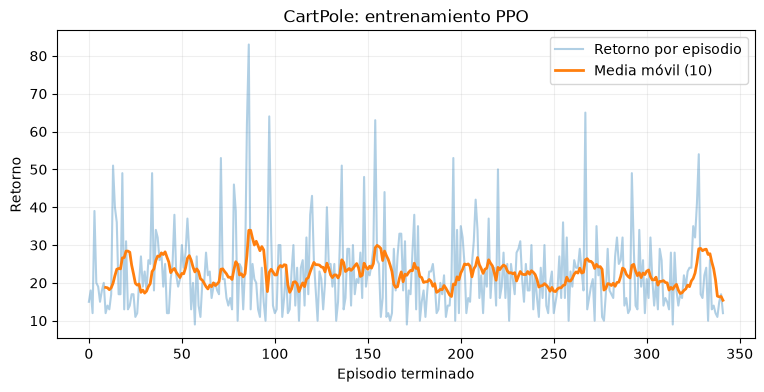

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
if returns_history:
    ax.plot(returns_history, alpha=0.35, label="Retorno por episodio")
    window = min(10, len(returns_history))
    moving = np.convolve(returns_history, np.ones(window)/window, mode="valid")
    ax.plot(np.arange(window-1, len(returns_history)), moving,
            linewidth=2, label=f"Media móvil ({window})")
ax.set(xlabel="Episodio terminado", ylabel="Retorno", title="CartPole: entrenamiento PPO")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

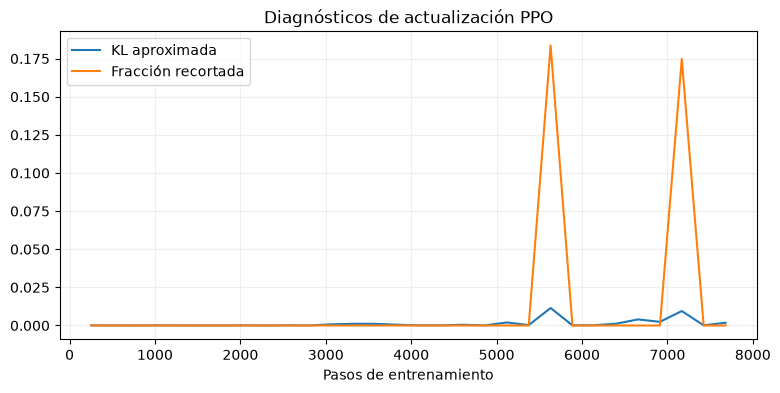

In [8]:
if len(history):
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(history[:, 0], history[:, 4], label="KL aproximada")
    ax.plot(history[:, 0], history[:, 5], label="Fracción recortada")
    ax.set(xlabel="Pasos de entrenamiento", title="Diagnósticos de actualización PPO")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.show()
else:
    print("Sin historial: primero ejecuta el entrenamiento.")

# <span style="color:#174ea6">11. Evaluación fuera del entrenamiento</span>

Evaluamos en semillas diferentes de la inicial y usamos la acción más probable (modo determinista). Para una comparación científica deben repetirse también los entrenamientos con varias semillas y contrastar políticas sobre los **mismos** escenarios de evaluación.

In [9]:
def evaluate_cartpole(model, seeds=range(3000, 3010)):
    test_env = gym.make("CartPole-v1")
    scores = []
    model.eval()
    for seed in seeds:
        state, _ = test_env.reset(seed=int(seed))
        total = 0.0
        while True:
            x = torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
            with torch.no_grad():
                dist, _ = model.distribution_and_value(x)
                action = int(torch.argmax(dist.logits, dim=-1).item())
            state, reward, terminated, truncated, _ = test_env.step(action)
            total += reward
            if terminated or truncated:
                break
        scores.append(total)
    test_env.close()
    model.train()
    return np.asarray(scores)

scores = evaluate_cartpole(model) if GYM_OK else np.asarray([])
if len(scores):
    print(f"Evaluación: media={scores.mean():.1f}, DE={scores.std(ddof=1):.1f}, "
      f"mínimo={scores.min():.0f}, máximo={scores.max():.0f}")

Evaluación: media=15.3, DE=1.3, mínimo=13, máximo=17


# <span style="color:#174ea6">12. Puente conceptual: de CartPole a Hydro-Lab</span>

| Componente | CartPole didáctico | Hydro-Lab S2.11 |
|---|---|---|
| Observación | 4 variables | 15 características observables |
| Acción | Discreta: izquierda/derecha | 3 componentes continuos normalizados en $[-1,1]$ |
| Actuadores | Fuerza sobre carro | Consignas de tres bombas |
| Episodio | Hasta 500 pasos | Hasta 96 pasos de 15 minutos |
| Recompensa | Supervivencia y equilibrio | Recompensa hidráulica sintética de S2.10 |
| Política | Categórica PyTorch escrita aquí | PPO integrado con Stable-Baselines3 |
| Evaluación | Semillas independientes | Semillas de escenarios y modelos; líneas base hidráulicas |

**Consecuencia matemática:** para acciones continuas, la distribución del actor deja de ser categórica. Una implementación PPO puede emplear una distribución gaussiana parametrizada por una red, con el tratamiento apropiado de límites y transformaciones de acciones. No debemos trasladar literalmente `Categorical` a Hydro-Lab.

<img src="../Imagenes/arquitectura_laboratorio_G2.4.png" width="1000"/>

*Figura 3. Red de transporte de hidrocarburos y capas de Hydro-Lab G2.4.*

# <span style="color:#174ea6">13. Hydro-Lab S2.11: mapa de la implementación real</span>

Esta sección está basada en el **Manual Hydro-Lab S2.11 G3.1** y el documento de continuidad del proyecto. **No sustituye una auditoría línea por línea de los módulos Python del repositorio local.** Cuando trabajes en el Mac del laboratorio, abre los archivos indicados para verificar firmas, hiperparámetros por defecto y transformaciones exactas.

## <span style="color:#bd232b">13.1 Separación de responsabilidades</span>

| Archivo | Responsabilidad que debe examinar el estudiante |
|---|---|
| `src/hydro_lab/agents.py` | Contrato `Agent.act(observation, deterministic=True)`; acciones de tres componentes |
| `src/hydro_lab/ppo_s211.py` | Adaptación de PPO al entorno hidráulico; construcción, carga y evaluación del agente |
| `src/hydro_lab/s211_train04.py` | Entrenamiento instrumentado, validación periódica y exportación de diagnósticos |
| `src/hydro_lab/s211_study05.py` | Diagnósticos y experimentos con varias semillas |
| `dashboard/ppo_tab.py` | Interfaz de configuración, entrenamiento, evaluación e historial |
| `dashboard/ppo_worker.py` | Ejecución del trabajo de PPO desde la interfaz |
| `dashboard/app.py` | Aplicación principal y pestañas |
| `src/hydro_lab/` | Simulador físico, recompensas y políticas de referencia |

**Distinción fundamental:** la interfaz Streamlit no es el algoritmo; PPO se ejecuta sobre el simulador mediante el adaptador del agente y la instrumentación de entrenamiento.

<img src="../Imagenes/Arquitectura_PPO_control_hidrocarburos.png" width="1000"/>

*Figura 4. Arquitectura y flujo de entrenamiento PPO aplicado a Hydro-Lab. Ilustración nueva de la colección, ya generada.*

## <span style="color:#bd232b">13.2 Contrato de interacción</span>

La política recibe un vector observable de dimensión **15**, no el estado físico privilegiado completo. Su salida contiene **tres acciones normalizadas** dentro de $[-1,1]$, una por bomba. El entorno interpreta esas acciones como consignas hidráulicas y aplica sus restricciones y mecanismos de seguridad.

El flujo conceptual es

$$
o_t \in \mathbb R^{15}
\xrightarrow{\pi_\theta}
a_t \in [-1,1]^3
\xrightarrow{\text{adaptador / simulador}}
(s_{t+1},r_t,\text{terminated},\text{truncated}).
$$

Una acción solicitada por el agente puede diferir de la efectivamente aplicada después del tratamiento de seguridad. **No confundas la acción propuesta por la red con la acción ejecutada por el simulador.**

El contrato de agentes prohíbe usar como entrada de política información privilegiada como `info['evaluation_truth']`. Ese campo puede ser útil para auditoría del simulador, pero utilizarlo como observación sería una fuga de información.

## <span style="color:#bd232b">13.3 ¿Qué aprende exactamente PPO?</span>

PPO ajusta parámetros de una política para maximizar la **recompensa definida por Hydro-Lab**. No aprende directamente a «operar mejor» en cualquier sentido industrial. La recompensa combina consecuencias del control hidráulico y penalizaciones sintéticas heredadas de S2.10; los costos se expresan en **unidades monetarias sintéticas (UM)**.

Esto obliga a separar tres planos:

1. **Optimización:** la suma de recompensas que PPO intenta mejorar.
2. **Operación:** energía, demanda no atendida, intervenciones y duración efectiva de episodios.
3. **Seguridad:** restricciones, acciones inviables y terminaciones anticipadas.

Un retorno mayor puede coexistir con resultados desfavorables en alguna métrica secundaria. Por eso el laboratorio compara contra controladores de referencia.

## <span style="color:#bd232b">13.4 Entrenamiento instrumentado: un ejemplo reproducible</span>

Desde la raíz del repositorio, con el entorno `hydro-lab` activado, el documento de continuidad registra esta corrida de referencia:

```bash
python -m hydro_lab.s211_train04 \
  --output resultados/s211_ppo_instrumentado_04 \
  --timesteps 4096 \
  --seed 42 \
  --n-steps 256 \
  --batch-size 64 \
  --eval-every 1024 \
  --validation-count 8
```

**Lectura de los parámetros:** `timesteps` cuenta interacciones con el entorno; `n_steps` determina el tamaño del rollout; `batch_size` el minibatch de optimización; `eval_every` el intervalo de validación y `validation-count` el número de escenarios reservados.

Esta corrida histórica alcanzó 4096 pasos y 54 episodios, pero **no demostró convergencia**. Sus retornos de validación no mejoraron de forma monótona. No se presenta aquí como un modelo industrial ni como evidencia de superioridad.

## <span style="color:#bd232b">13.5 La quinta pestaña: tres momentos del ciclo de vida</span>

**Entrenar y observar.** El estudiante define semilla, presupuesto y parámetros, lanza una corrida y observa métricas y validaciones. Una configuración corta documentada es semilla 44, `timesteps=1024`, `n_steps=256`, `batch_size=64`, `eval_every=512` y cuatro escenarios de validación. Sirve para comprobar la ejecución, **no para concluir calidad**.

**Evaluar y comparar.** Se recupera un checkpoint, se selecciona una partición y se evalúa sin modificar los parámetros de la política. Se compara PPO con `constant`, `demand_feedback` y `health_robust` bajo escenarios emparejados.

**Consultar resultados.** Se recuperan corridas, curvas, evaluaciones previas y diagnósticos multisemilla.

**Importante:** seleccionar otro controlador en la barra lateral general no convierte automáticamente ese controlador en PPO. El flujo PPO se administra en su propia pestaña.

## <span style="color:#bd232b">13.6 Anatomía del checkpoint y los CSV</span>

La aplicación guarda corridas independientes bajo `resultados/s211_dashboard/`. En el checkpoint se conservan:

- `ppo_model.zip`: parámetros del agente PPO.
- `normalization.pkl`: estadísticas de normalización necesarias en inferencia.
- `metadata.json`: configuración y procedencia.

La corrida instrumentada también produce:

- `ppo_diagnostics.csv`: métricas del optimizador.
- `episodes_training.csv`: episodios de entrenamiento.
- `validation_during_training.csv`: validación periódica.

**Regla esencial:** no se debe evaluar el modelo cargando solamente `ppo_model.zip`. Es necesario recuperar la normalización del entrenamiento y evitar actualizar sus estadísticas durante inferencia.

Los resultados de evaluación pueden incluir `episodes.csv`, `paired.csv`, `summary_by_seed.csv`, `between_seed_variability.csv` y `report.json`. La existencia de cada archivo depende del procedimiento ejecutado.

## <span style="color:#bd232b">13.7 Comparación pareada y variabilidad entre entrenamientos</span>

Para una semilla de entrenamiento $s$, un escenario $j$ y una referencia $b$:

$$
\Delta R_{s,j,b}=R_{\mathrm{PPO},s,j}-R_{b,s,j}.
$$

El emparejamiento compara políticas sobre el **mismo escenario**; evita atribuir a la política diferencias debidas a escenarios iniciales distintos. Una diferencia positiva favorece a PPO **en retorno**, no necesariamente en consumo energético o seguridad.

También hay dos fuentes de variación distintas:
- **Entre escenarios:** una misma política responde de manera diferente a distintas condiciones.
- **Entre semillas de entrenamiento:** dos redes PPO entrenadas con semillas diferentes pueden terminar con políticas distintas.

Una sola corrida no cuantifica la segunda fuente. El estudio multisemilla del proyecto conserva modelos de semillas 41, 42 y 43. En esa exploración PPO no superó sistemáticamente al controlador constante. Esa observación es un resultado docente valioso, no un defecto que deba ocultarse.

## <span style="color:#bd232b">13.8 Terminación anticipada: diagnóstico indispensable</span>

Un episodio puede completar su horizonte (`truncated`) o terminar antes por una condición terminal (`terminated`). Hydro-Lab registra, entre otras, la causa `NO_SAFE_ACTION_OR_STOP`: el simulador no encuentra una acción hidráulica factible ni una parada segura bajo sus restricciones.

En la pestaña **Comparar estrategias de control**, los diagnósticos agregados permiten estudiar tasas y causas de terminación. Al analizar PPO se deben examinar asimismo los episodios y resultados de evaluación, sin asumir que una recompensa alta equivale a operación sostenida.

Compara:
- proporción de episodios terminados anticipadamente;
- distribución de causas entre los episodios terminados;
- paso medio de terminación;
- recompensa, energía y demanda no atendida.

**Cuidado estadístico:** las proporciones entre episodios terminados y las tasas sobre el total de episodios tienen denominadores diferentes.

## <span style="color:#bd232b">13.9 Lectura crítica del código local (actividad de cierre)</span>

Abre el repositorio local y responde, **citando archivo, función y línea de tu versión**:

1. ¿Dónde se construye el espacio de observación de 15 componentes? ¿Qué normalización recibe?
2. ¿Dónde se declara el espacio de acciones de tres componentes? ¿Cómo se transforma la salida en consignas de bombas?
3. ¿En qué función se calcula la recompensa? ¿Cuáles son sus componentes y unidades?
4. ¿Qué clase o llamada crea el modelo PPO de Stable-Baselines3? ¿Qué valores efectivos toman `gamma`, `gae_lambda`, `clip_range`, `ent_coef`, `n_epochs` y `learning_rate`? **No infieras los valores de este cuaderno:** compruébalos en el código.
5. ¿Cómo se manejan `terminated` y `truncated` al llegar a 96 pasos o a una situación inviable?
6. ¿Dónde se guarda y recupera `normalization.pkl`?
7. ¿Cómo se evita utilizar los escenarios de validación para actualizar el agente?
8. ¿Dónde se generan `paired.csv` y los diagnósticos de terminación?

**Ejercicio integrador:** identifica una correspondencia entre cada bloque del código PyTorch de CartPole (`collect_rollout`, `compute_gae`, `ppo_update`, `evaluate_cartpole`) y el componente equivalente del flujo Hydro-Lab/SB3. Cuando SB3 encapsule una operación, indícalo explícitamente en vez de inventar una función local.

In [10]:
# Comprobación algebraica independiente de Gymnasium.
import numpy as np

def clipped_surrogate(ratio, advantage, eps=0.2):
    return np.minimum(ratio * advantage, np.clip(ratio, 1-eps, 1+eps) * advantage)

assert np.isclose(clipped_surrogate(1.5, 2.0), 2.4)
assert np.isclose(clipped_surrogate(0.5, -2.0), -1.6)
assert np.isclose(clipped_surrogate(1.1, 2.0), 2.2)
print("Objetivo recortado: pruebas algebraicas superadas.")

Objetivo recortado: pruebas algebraicas superadas.


# <span style="color:#174ea6">14. Actividades y preguntas</span>

**A. Clipping.** Con $\epsilon=0.2$, calcula a mano el objetivo para $A=2$ y $A=-2$ con razones $r=0.6,0.9,1.0,1.1,1.4$. ¿Dónde aparece una meseta?

**B. GAE.** Fija $\gamma=0.99$ y compara $\lambda=0,0.5,0.95,1$ en una secuencia corta de recompensas. ¿Qué cambia?

**C. Estabilidad.** Entrena CartPole con `clip_eps=0.1` y `clip_eps=0.3`, manteniendo las demás condiciones. Repite con varias semillas antes de sacar conclusiones.

**D. Diagnóstico.** ¿Por qué un modelo que acumula mayor recompensa puede terminar más episodios anticipadamente?

**E. Hydro-Lab.** Explica por qué comparar PPO con `constant` y `demand_feedback` es indispensable, aunque PPO use una red neuronal más sofisticada.

**F. Integridad.** ¿Qué error se comete al evaluar el checkpoint sin `normalization.pkl`? ¿Qué ocurre si se elige el mejor modelo mirando repetidamente el conjunto de prueba?

# <span style="color:#174ea6">15. Referencias</span>

1. Schulman, J., Wolski, F., Dhariwal, P., Radford, A. y Klimov, O. (2017). *Proximal Policy Optimization Algorithms*. arXiv:1707.06347. https://arxiv.org/abs/1707.06347
2. Schulman, J., Moritz, P., Levine, S., Jordan, M. y Abbeel, P. (2016). *High-Dimensional Continuous Control Using Generalized Advantage Estimation*. https://arxiv.org/abs/1506.02438
3. Sutton, R. S. y Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, 2.ª ed. http://incompleteideas.net/book/the-book-2nd.html
4. Documentación Gymnasium: https://gymnasium.farama.org/
5. Documentación Stable-Baselines3 PPO: https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html
6. **Material interno del curso:** *Manual de uso Hydro-Lab S2.11, G3.1* y *Hydro-Lab S2.11 — Estado y continuidad G0.1*.

**Nota editorial:** las dos imágenes originales referenciadas en este cuaderno aún deben generarse en `imagenes/`. Los detalles específicos de implementación de Hydro-Lab se han documentado con los materiales disponibles; para una correspondencia exacta línea por línea se requieren los módulos Python locales.

## <span style="color:#bd232b">Créditos, procedencia de figuras y licencia</span>

**Autores:** Álvaro Montenegro, Daniel Montenegro y Pilar Montenegro. **Docente:** Álvaro Montenegro. **Institución:** Universidad de los Andes - Ecopetrol. **Producción académica:** Aprendizaje Profundo.

**Licencia:** MIT para las contribuciones originales de esta edición; no altera las licencias ni atribuciones de bibliografía, software ni material gráfico de terceros.

**Fuentes directas de consolidación:** `15_ar_PPO.ipynb` (base), `12_ar_Gradientes_Politica.ipynb`, `13_ar_Actor_Critico.ipynb` y manuales Hydro-Lab S2.11. Los archivos originales permanecen intactos.

**Figuras referenciadas en `../Imagenes/`:** `logo-final-ap.png` (existente), `ppo_objetivo_clipped.png` (figura nueva ya generada), `ppo_actor_critico_flujo.png` (figura nueva ya generada), `arquitectura_laboratorio_G2.4.png` (existente del proyecto).